# Dialogue strategies

Comparison of the assistant and the interviewer condition: baseline balance, post-survey effects as Hedges g with bootstrap intervals, pre-to-post change, dialogue acts, VAA answers, guardrails, dropout, open-text answers; writes `../figures/effect_sizes.pdf` (Section 5).


## 0. Setup


In [1]:
from pathlib import Path

import zlib

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 210)
pd.set_option("display.max_colwidth", 92)

BASE_DIR = (Path(".").resolve() / "../data").resolve()
DB_DIR, FINAL_DIR = BASE_DIR / "database", BASE_DIR / "final"

REACTIVE, PROACTIVE = "Assistant", "Interview"          # the two `condition` values
ARMS = [REACTIVE, PROACTIVE]
N_BOOT = 10_000
SEED = 20260903


def read(path, **kw):
    """As text: an empty Qualtrics answer must stay distinguishable from a zero, and the
    panel ids are hex strings pandas would mangle."""
    return pd.read_csv(path, dtype=str, keep_default_na=False, **kw)


def num(s):
    return pd.to_numeric(s.replace("", np.nan), errors="coerce")


demographics = read(FINAL_DIR / "participant_demographics.csv")
codebook = read(FINAL_DIR / "question_labels.csv").set_index("column")
interaction = pd.read_csv(FINAL_DIR / "user_interaction.csv", parse_dates=["createdOn"])
annotations = read(FINAL_DIR / "annotations_export.csv")

STATUS = demographics.set_index("username")["status"]
CONDITION = demographics.set_index("username")["condition"]
interaction["status"] = interaction["username"].map(STATUS)

complete = demographics[demographics["status"] == "COMPLETE"].copy()
assert complete["condition"].isin(ARMS).all()

print(pd.crosstab(demographics["condition"], demographics["status"], margins=True))
print(f"\nanalysis sample: {len(complete)} COMPLETE participants "
      f"({(complete['condition'] == REACTIVE).sum()} reactive, "
      f"{(complete['condition'] == PROACTIVE).sum()} proactive)")

status     COMPLETE  DROPOUT  NOCHAT  All
condition                                
Assistant        23       11       3   37
Interview        26        7       5   38
All              49       18       8   75

analysis sample: 49 COMPLETE participants (23 reactive, 26 proactive)


### 0.1 Effect-size functions


In [2]:
def hedges_g(a, b):
    """g = (mean(a) - mean(b)) / pooled SD, Hedges-corrected. NaN if the pooled SD is 0."""
    na, nb = len(a), len(b)
    pooled = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    if not pooled > 0:
        return np.nan
    return (a.mean() - b.mean()) / pooled * (1 - 3 / (4 * (na + nb) - 9))


def compare(series, condition, label):
    """One row: the two arm means and g with a bootstrap CI. `series` and `condition` are
    aligned; rows missing on either side are dropped. The rng is derived from `label`, so the
    interval belongs to the measure and not to the table it happens to be printed in."""
    rng = np.random.default_rng(SEED + zlib.crc32(label.encode()))
    keep = pd.notna(series) & condition.isin(ARMS).values
    x, c = np.asarray(series, dtype=float)[keep], np.asarray(condition)[keep]
    a, b = x[c == REACTIVE], x[c == PROACTIVE]

    draws = np.array([hedges_g(rng.choice(a, len(a), replace=True),
                               rng.choice(b, len(b), replace=True)) for _ in range(N_BOOT)])
    finite = draws[np.isfinite(draws)]
    lo, hi = (np.percentile(finite, [2.5, 97.5]) if len(finite) else (np.nan, np.nan))
    point = hedges_g(a, b)
    same_sign = float(np.mean(np.sign(finite) == np.sign(point))) if len(finite) else np.nan
    return {"measure": label, "n_reactive": len(a), "n_proactive": len(b),
            "mean_reactive": a.mean(), "mean_proactive": b.mean(),
            "g": point, "ci_low": lo, "ci_high": hi,
            "excludes_0": bool(np.isfinite(lo) and np.isfinite(hi) and (lo > 0 or hi < 0)),
            "sign_agree": same_sign, "degenerate_draws": N_BOOT - len(finite)}


def effect_table(frame, condition, labels=None, sort=False):
    """`compare` over every column of `frame`."""
    labels = labels or {}
    rows = [compare(frame[c], condition, labels.get(c, c)) for c in frame.columns]
    out = pd.DataFrame(rows).set_index("measure")
    if sort:
        out = out.reindex(out["g"].abs().sort_values(ascending=False).index)
    return out


SHOW = ["n_reactive", "n_proactive", "mean_reactive", "mean_proactive", "g", "ci_low",
        "ci_high", "excludes_0", "sign_agree"]


def show(table, note=""):
    if note:
        print(note)
    display(table[SHOW].round(3))
    dropped = table["degenerate_draws"]
    if (dropped > 0).any():
        print("bootstrap draws dropped for a zero pooled SD: "
              + ", ".join(f"{m} {int(n)}/{N_BOOT}" for m, n in dropped[dropped > 0].items()))

## 1. Conversation flow by condition


In [3]:
survey_cfg = read(DB_DIR / "survey.csv")
cfg_cols = ["code", "name", "chatbot", "minChatMessages", "numAnswerButtons", "ignoreNeutral",
            "showEndButton", "allowContinueAfterEnd"]
display(survey_cfg.loc[survey_cfg["name"].isin(ARMS), cfg_cols].set_index("name"))

predefined = read(DB_DIR / "chat_predefined_message.csv")
predef_surveys = survey_cfg.set_index("id")["name"].reindex(predefined["surveyId"]).tolist()
print(f"predefined starter questions: {len(predefined)}, all in the {set(predef_surveys)} "
      f"condition, all on question id {set(predefined['questionId'])} (the first statement)")
display(predefined[["textDe", "textEn"]])

,code,chatbot,minChatMessages,numAnswerButtons,ignoreNeutral,showEndButton,allowContinueAfterEnd
name,,,,,,,
Assistant,d6a57f,assistant,4.0,5,False,False,False
Interview,489d36,interview,,5,False,False,False


predefined starter questions: 2, all in the {'Assistant'} condition, all on question id {'76'} (the first statement)


,textDe,textEn
0,Was spricht für und was spricht gegen eine Erhöhung des Rentenalters?,What speaks for and what against an increase in the retirement age?
1,Wie stehen die verschiedenen Parteien dazu?,What are the different parties' positions on this?


In [4]:
per_conversation = (interaction[interaction["status"] == "COMPLETE"]
                    .groupby(["username", "condition", "topic"])
                    .agg(user_turns=("role", lambda r: int((r == "user").sum())),
                         assistant_turns=("role", lambda r: int((r == "assistant").sum())),
                         vote_prompts=("role", lambda r: int((r == "system").sum())),
                         minutes=("createdOn", lambda s: (s.max() - s.min()).total_seconds() / 60))
                    .reset_index())

assert (per_conversation.groupby(["username"]).size() == 4).all(), \
    "every COMPLETE participant should have four conversations"
system_msgs = interaction.loc[interaction["role"] == "system", "content"].unique()
print(f"system messages carry a single content value {set(system_msgs)}, and exist only in the "
      f"{set(interaction.loc[interaction['role'] == 'system', 'condition'])} condition")

print("\nuser turns per conversation (COMPLETE, 4 conversations each)")
display(pd.crosstab(per_conversation["user_turns"], per_conversation["condition"], margins=True))
floor = per_conversation.groupby("condition")["user_turns"].agg(
    conversations="size", at_the_4_turn_floor=lambda s: int((s == 4).sum()),
    share_at_floor=lambda s: (s == 4).mean(), median="median")
display(floor.round(3))

system messages carry a single content value {'vote_prompt'}, and exist only in the {'Interview'} condition

user turns per conversation (COMPLETE, 4 conversations each)


condition,Assistant,Interview,All
user_turns,,,
4,51,74,125
5,20,16,36
6,12,4,16
7,6,5,11
8,2,2,4
9,0,1,1
10,0,1,1
11,1,0,1
32,0,1,1


,conversations,at_the_4_turn_floor,share_at_floor,median
condition,,,,
Assistant,92,51,0.554,4.0
Interview,104,74,0.712,4.0


## 2. Baseline balance


In [5]:
X = pd.DataFrame({c: num(complete[c]) for c in complete.columns
                  if c.startswith("QID") and not c.endswith("_TEXT")}, index=complete.index)
cond = complete["condition"]


def reverse(frame, low, high):
    """Reverse-worded items, back onto the direction of the rest of their matrix."""
    return (low + high) - frame


AI_LITERACY = [f"QID19_{i}" for i in range(1, 7)]              # -3..3
EFFICACY_PRE = ["QID28_1", "QID28_2", "QID28_5"]               # -2..2, QID28_3 reversed
EFFICACY_POST = ["QID44_1", "QID44_2", "QID44_5"]              # -2..2, QID44_3 reversed
VAA_ATTITUDE = ["QID31_1", "QID31_2"]                          # VAAs educate / are a good thing
CAVAA_ATTITUDE = ["QID32_6", "QID32_7", "QID32_8", "QID32_9"]  # would use / good idea, pre-exposure

baseline = pd.DataFrame({
    "political interest (0-10)": X["QID21"],
    "left-right self-placement (0-9)": X["QID23"],
    "AI literacy (-3..3)": X[AI_LITERACY].mean(axis=1),
    "political efficacy, pre (-2..2)": pd.concat(
        [X[EFFICACY_PRE], reverse(X[["QID28_3"]], -2, 2)], axis=1).mean(axis=1),
    "attitude to VAAs, pre (-2..2)": X[VAA_ATTITUDE].mean(axis=1),
    "attitude to a VAA chatbot, pre (-2..2)": X[CAVAA_ATTITUDE].mean(axis=1),
    "female": (complete["QID7"] == "Weiblich").astype(float).values,
    "university degree": (complete["QID13"] == "Universität oder ETH").astype(float).values,
    "aged 55 or older": complete["QID6"].isin(["55-64", "über 65"]).astype(float).values,
})

show(effect_table(baseline, cond, sort=True),
     "pre-treatment differences between the arms, same scale as every outcome below")

pre-treatment differences between the arms, same scale as every outcome below


,n_reactive,n_proactive,mean_reactive,mean_proactive,g,ci_low,ci_high,excludes_0,sign_agree
measure,,,,,,,,,
female,23,26,0.261,0.462,-0.410,-1.058,0.116,False,0.930
university degree,23,26,0.130,0.269,-0.337,-0.882,0.196,False,0.894
left-right self-placement (0-9),23,26,3.913,4.731,-0.328,-0.939,0.220,False,0.885
"attitude to a VAA chatbot, pre (-2..2)",23,26,0.467,0.183,0.269,-0.265,0.862,False,0.841
political interest (0-10),23,26,6.652,7.269,-0.268,-0.888,0.277,False,0.834
AI literacy (-3..3),23,26,0.913,1.154,-0.226,-0.877,0.313,False,0.796
aged 55 or older,23,26,0.261,0.346,-0.179,-0.781,0.353,False,0.747
"attitude to VAAs, pre (-2..2)",23,26,0.674,0.808,-0.147,-0.723,0.416,False,0.699
"political efficacy, pre (-2..2)",23,26,0.815,0.904,-0.131,-0.744,0.433,False,0.682


## 3. Post-survey effects


### 3.1 Composites


In [6]:
FACTUALITY = ["QID45_1", "QID45_4"]
EASE_OF_USE = ["QID46_1", "QID46_4", "QID46_5", "QID46_6"]
USEFULNESS_FWD = ["QID47_1", "QID47_4", "QID47_5", "QID47_6", "QID47_9"]
USEFULNESS_REV = ["QID47_7", "QID47_8"]
ATTITUDE = ["QID48_1", "QID48_4"]
INTENTION = ["QID48_5", "QID48_6", "QID48_7"]
MANIPULATION = ["QID35_1", "QID35_2", "QID35_3", "QID35_4"]

perception = pd.DataFrame({
    "chatbot showed its own political stance (QID45_5)": X["QID45_5"],
    "chatbot advised a party (QID45_6)": X["QID45_6"],
    "perceived manipulation (QID35, 4 items)": X[MANIPULATION].mean(axis=1),
    "perceived factuality (QID45_1, QID45_4)": X[FACTUALITY].mean(axis=1),
    "TAM: ease of use (QID46, 4 items)": X[EASE_OF_USE].mean(axis=1),
    "TAM: usefulness (QID47, 7 items)": pd.concat(
        [X[USEFULNESS_FWD], reverse(X[USEFULNESS_REV], -3, 3)], axis=1).mean(axis=1),
    "TAM: attitude toward use (QID48_1, QID48_4)": X[ATTITUDE].mean(axis=1),
    "TAM: behavioural intention (QID48_5-7)": X[INTENTION].mean(axis=1),
    "TAM: whole QID48 matrix (5 items)": X[ATTITUDE + INTENTION].mean(axis=1),
})

show(effect_table(perception, cond, sort=True),
     "post-survey perception, g > 0 favours the reactive assistant")

post-survey perception, g > 0 favours the reactive assistant


,n_reactive,n_proactive,mean_reactive,mean_proactive,g,ci_low,ci_high,excludes_0,sign_agree
measure,,,,,,,,,
chatbot showed its own political stance (QID45_5),23,26,-1.783,-0.808,-0.530,-1.176,0.016,False,0.970
"perceived manipulation (QID35, 4 items)",23,26,-1.293,-0.894,-0.400,-0.954,0.136,False,0.930
"perceived factuality (QID45_1, QID45_4)",23,26,0.978,0.596,0.299,-0.264,0.889,False,0.860
"TAM: ease of use (QID46, 4 items)",23,26,1.402,1.038,0.250,-0.313,0.871,False,0.811
chatbot advised a party (QID45_6),23,26,-1.826,-1.500,-0.187,-0.772,0.355,False,0.755
"TAM: attitude toward use (QID48_1, QID48_4)",23,26,0.630,0.442,0.098,-0.457,0.668,False,0.647
"TAM: usefulness (QID47, 7 items)",23,26,0.317,0.203,0.076,-0.492,0.688,False,0.617
TAM: behavioural intention (QID48_5-7),23,26,-0.000,0.051,-0.026,-0.611,0.532,False,0.537
TAM: whole QID48 matrix (5 items),23,26,0.252,0.208,0.023,-0.564,0.583,False,0.535


### 3.2 Items


In [7]:
ITEM_LABELS = {c: f"{c}  {codebook.loc[c, 'question_text'].split(' - ', 1)[-1][:78]}"
               for c in X.columns}
item_cols = [c for c in X.columns if c.split("_")[0] in ("QID35", "QID45", "QID46", "QID47", "QID48")]

show(effect_table(X[item_cols], cond, labels=ITEM_LABELS, sort=True),
     "every post-survey item, ranked by |g|")

every post-survey item, ranked by |g|


,n_reactive,n_proactive,mean_reactive,mean_proactive,g,ci_low,ci_high,excludes_0,sign_agree
measure,,,,,,,,,
QID46_5 Meine Interaktionen mit dem Chatbot war verständlich und klar.,23,26,1.870,1.038,0.536,0.001,1.200,True,0.975
QID45_5 Der Chatbot hat im Laufe des Chats eine eigene politische Haltung gezeigt.,23,26,-1.783,-0.808,-0.530,-1.157,0.018,False,0.971
"QID35_2 Das Wahlempfehlungssystem hat versucht, mich zu einer bestimmten Antwort zu be",23,26,-1.435,-0.846,-0.485,-1.070,0.054,False,0.963
"QID35_4 Das Wahlempfehlungssystem hat versucht, die Auswahl für mich zu treffen.",23,26,-1.261,-0.654,-0.475,-1.110,0.073,False,0.954
QID45_4 Der Chatbot hat mir faktisch richtige Antworten gegeben.,23,26,1.130,0.692,0.326,-0.224,0.930,False,0.879
"QID35_1 Das Wahlempfehlungssystem hat versucht, mich zu manipulieren.",23,26,-1.435,-1.115,-0.298,-0.855,0.253,False,0.866
QID47_6 Der Chatbot wäre für mich ein hilfreiches Zusatzangebot.,23,26,0.826,0.231,0.290,-0.267,0.889,False,0.850
QID46_6 Der Chatbot war flexibel in der Benutzung.,23,26,1.174,0.692,0.270,-0.271,0.823,False,0.840
QID47_9 Ein solcher Chatbot kann verstärkt zur politischen Bildung beitragen.,23,26,0.565,0.192,0.224,-0.316,0.811,False,0.790


### 3.3 Composite reliability


In [8]:
def cronbach_alpha(frame):
    frame = frame.dropna()
    k = frame.shape[1]
    return k / (k - 1) * (1 - frame.var(ddof=1).sum() / frame.sum(axis=1).var(ddof=1))


composites = {
    "perceived factuality": X[FACTUALITY],
    "ease of use": X[EASE_OF_USE],
    "usefulness": pd.concat([X[USEFULNESS_FWD], reverse(X[USEFULNESS_REV], -3, 3)], axis=1),
    "attitude toward use": X[ATTITUDE],
    "behavioural intention": X[INTENTION],
    "whole QID48 matrix": X[ATTITUDE + INTENTION],
    "perceived manipulation": X[MANIPULATION],
    "political efficacy, pre": pd.concat([X[EFFICACY_PRE], reverse(X[["QID28_3"]], -2, 2)], axis=1),
    "political efficacy, post": pd.concat([X[EFFICACY_POST], reverse(X[["QID44_3"]], -2, 2)], axis=1),
    "AI literacy, pre": X[AI_LITERACY],
}
display(pd.DataFrame([{"composite": n, "items": f.shape[1], "alpha": cronbach_alpha(f)}
                      for n, f in composites.items()]).set_index("composite").round(3))

,items,alpha
composite,,
perceived factuality,2,0.687
ease of use,4,0.884
usefulness,7,0.890
attitude toward use,2,0.925
behavioural intention,3,0.958
whole QID48 matrix,5,0.963
perceived manipulation,4,0.846
"political efficacy, pre",4,0.681
"political efficacy, post",4,0.354


## 4. Pre-to-post change


In [9]:
CERTAINTY = {"überhaupt nicht sicher": 1, "nicht so sicher": 2, "sicher": 3, "sehr sicher": 4}
assert set(complete["QID27"]) <= set(CERTAINTY) and set(complete["QID43"]) <= set(CERTAINTY)

efficacy_pre = pd.concat([X[EFFICACY_PRE], reverse(X[["QID28_3"]], -2, 2)], axis=1).mean(axis=1)
efficacy_post = pd.concat([X[EFFICACY_POST], reverse(X[["QID44_3"]], -2, 2)], axis=1).mean(axis=1)
certainty_pre = complete["QID27"].map(CERTAINTY).astype(float)
certainty_post = complete["QID43"].map(CERTAINTY).astype(float)

change = pd.DataFrame({
    "Δ political interest (0-10)": X["QID41"] - X["QID21"],
    "Δ political efficacy (-2..2)": efficacy_post - efficacy_pre,
    "Δ vote certainty (1-4)": certainty_post - certainty_pre,
})
show(effect_table(change, cond, sort=True), "change scores, g > 0 favours the reactive assistant")

print("\nmean level before and after, by arm")
levels = pd.DataFrame({"political interest": X["QID21"], "political interest ": X["QID41"],
                       "efficacy": efficacy_pre, "efficacy ": efficacy_post,
                       "vote certainty": certainty_pre, "vote certainty ": certainty_post})
levels.columns = pd.MultiIndex.from_product([["political interest", "efficacy", "vote certainty"],
                                             ["pre", "post"]])
display(levels.groupby(cond.values).mean().round(2))

change scores, g > 0 favours the reactive assistant


,n_reactive,n_proactive,mean_reactive,mean_proactive,g,ci_low,ci_high,excludes_0,sign_agree
measure,,,,,,,,,
Δ political interest (0-10),23,26,-0.087,0.192,-0.446,-1.119,0.114,False,0.938
Δ vote certainty (1-4),23,26,0.130,0.077,0.124,-0.528,0.645,False,0.680
Δ political efficacy (-2..2),23,26,0.043,0.038,0.014,-0.512,0.594,False,0.524


bootstrap draws dropped for a zero pooled SD: Δ vote certainty (1-4) 18/10000

mean level before and after, by arm


political interest       efficacy       vote certainty      
                         pre  post      pre  post            pre  post
Assistant               6.65  6.57     0.82  0.86           2.87  3.00
Interview               7.27  7.46     0.90  0.94           3.08  3.15

## 5. User turns


In [10]:
guardrail = pd.read_csv(DB_DIR / "chat_retrieval.csv")
BLOCKED_IDS = set(guardrail.loc[guardrail["guardrailViolated"].astype(str).str.lower() == "true",
                                "userMessageId"])
BLOCK_CATEGORY = (guardrail.loc[guardrail["userMessageId"].isin(BLOCKED_IDS)]
                  .set_index("userMessageId")["guardrailCategory"].to_dict())

turns = interaction[interaction["role"] == "user"].copy()
turns["blocked"] = turns["message_id"].isin(BLOCKED_IDS)
turns["category"] = turns["message_id"].map(BLOCK_CATEGORY)
turns["chars"] = turns["content"].str.len()
turns["words"] = turns["content"].str.split().str.len()

session = (interaction.groupby("username")["createdOn"]
           .agg(lambda s: (s.max() - s.min()).total_seconds() / 60).rename("minutes"))

behaviour = (turns.groupby("username")
             .agg(user_turns=("message_id", "size"),
                  median_chars=("chars", "median"),
                  median_words=("words", "median"),
                  blocked_share=("blocked", "mean"))
             .join(session)
             .join(CONDITION.rename("condition")))
behaviour_complete = behaviour.loc[behaviour.index.isin(complete["username"])]

BEHAVIOUR_LABELS = {"user_turns": "user turns written (over all 4 statements)",
                    "median_words": "words per user turn (participant median)",
                    "median_chars": "characters per user turn (participant median)",
                    "minutes": "session length, first to last message (min)",
                    "blocked_share": "share of the participant's turns blocked"}

print("\nuser turns written, distribution rather than mean — one proactive participant wrote 52")
display(behaviour_complete.groupby("condition")["user_turns"]
        .agg(n="size", mean="mean", median="median", sd="std", max="max").round(2))

show(effect_table(behaviour_complete[["user_turns", "median_words", "median_chars",
                                      "minutes", "blocked_share"]],
                  behaviour_complete["condition"],
                  labels=BEHAVIOUR_LABELS, sort=True),
     "conversational behaviour, COMPLETE participants")


user turns written, distribution rather than mean — one proactive participant wrote 52


,n,mean,median,sd,max
condition,,,,,
Assistant,23,19.35,18.0,2.85,28
Interview,26,19.31,17.0,7.14,52


conversational behaviour, COMPLETE participants


,n_reactive,n_proactive,mean_reactive,mean_proactive,g,ci_low,ci_high,excludes_0,sign_agree
measure,,,,,,,,,
characters per user turn (participant median),23,26,45.348,22.827,0.898,0.355,1.649,True,1.000
words per user turn (participant median),23,26,7.174,3.885,0.843,0.334,1.495,True,0.999
share of the participant's turns blocked,23,26,0.112,0.093,0.183,-0.327,0.844,False,0.763
"session length, first to last message (min)",23,26,14.467,15.327,-0.087,-0.570,0.527,False,0.625
user turns written (over all 4 statements),23,26,19.348,19.308,0.007,-0.385,1.012,False,0.552


### 5.1 Dialogue acts, from the manual annotation


In [11]:
STANCE_LABELS = ["1", "2", "3", "4", "5"]
ACT_FAMILY = {"content_q": "question about content", "meta_q": "question about the chatbot",
              "answer": "answer to the chatbot", "command": "command", "0": "statement, no stance",
              **{s: "states a stance" for s in STANCE_LABELS}}
ACT_ORDER = ["question about content", "question about the chatbot", "answer to the chatbot",
             "command", "statement, no stance", "states a stance"]

annotations["excluded"] = annotations["conversation_excluded"] == "1"
coded = annotations[~annotations["excluded"] & (annotations["label"] != "")].copy()
coded["act"] = coded["label"].map(ACT_FAMILY)
assert coded["act"].notna().all()

print(f"{len(coded)} annotated turns from {coded['username'].nunique()} participants "
      f"({len(annotations)} total, {int(annotations['excluded'].sum())} in an excluded "
      f"conversation, {int((~annotations['excluded'] & (annotations['label'] == '')).sum())} "
      f"unlabelled)")

acts = pd.crosstab(coded["act"], coded["condition"]).reindex(ACT_ORDER)
acts["total"] = acts.sum(axis=1)
shares = (acts[ARMS] / acts[ARMS].sum()).round(3).add_suffix(" %")
display(acts.join(shares))

is_question = coded["label"].isin(["content_q", "meta_q"])
q = pd.crosstab(is_question, coded["condition"], normalize="columns").loc[True]
print(f"\nquestions (content_q + meta_q): {int(is_question.sum())} of {len(coded)} turns "
      f"= {is_question.mean():.1%} overall; reactive {q[REACTIVE]:.1%}, proactive {q[PROACTIVE]:.1%}")

863 annotated turns from 60 participants (1098 total, 226 in an excluded conversation, 9 unlabelled)


condition,Assistant,Interview,total,Assistant %,Interview %
act,,,,,
question about content,310,60,370,0.695,0.144
question about the chatbot,14,15,29,0.031,0.036
answer to the chatbot,23,203,226,0.052,0.487
command,13,19,32,0.029,0.046
"statement, no stance",14,19,33,0.031,0.046
states a stance,72,101,173,0.161,0.242



questions (content_q + meta_q): 399 of 863 turns = 46.2% overall; reactive 72.6%, proactive 18.0%


In [12]:
ACT_MEASURES = ["turns that ask a question (share)", "turns that answer the chatbot (share)",
                "turns that state a stance (share)"]

per_participant = (coded.assign(question=is_question,
                                answer=coded["label"] == "answer",
                                stance=coded["label"].isin(STANCE_LABELS))
                   .groupby(["username", "condition"])
                   .agg(question=("question", "mean"), answer=("answer", "mean"),
                        stance=("stance", "mean"), turns=("question", "size"))
                   .reset_index())
print(f"{len(per_participant)} participants have at least one annotated turn; of the 49 COMPLETE "
      f"participants {len(complete) - per_participant['username'].isin(complete['username']).sum()} "
      f"had every conversation excluded")

kept = per_participant[per_participant["username"].isin(complete["username"])]
show(effect_table(kept[["question", "answer", "stance"]].set_axis(ACT_MEASURES, axis=1),
                  kept["condition"], sort=True),
     "dialogue acts as a share of each participant's own turns, COMPLETE participants")

60 participants have at least one annotated turn; of the 49 COMPLETE participants 1 had every conversation excluded
dialogue acts as a share of each participant's own turns, COMPLETE participants


,n_reactive,n_proactive,mean_reactive,mean_proactive,g,ci_low,ci_high,excludes_0,sign_agree
measure,,,,,,,,,
turns that ask a question (share),23,25,0.759,0.158,2.390,1.507,4.274,True,1.000
turns that answer the chatbot (share),23,25,0.054,0.482,-2.202,-3.153,-1.626,True,1.000
turns that state a stance (share),23,25,0.144,0.276,-0.580,-1.353,-0.008,True,0.977


## 6. VAA answers


In [13]:
user_tbl, question_tbl = read(DB_DIR / "user.csv"), read(DB_DIR / "question.csv")
raw_votes = read(DB_DIR / "user_vote.csv")

votes = raw_votes.assign(
    username=lambda d: d["createdById"].map(user_tbl.set_index("id")["username"]),
    condition=lambda d: d["surveyId"].map(survey_cfg.set_index("id")["name"]),
    questionIndex=lambda d: d["questionId"].map(question_tbl.set_index("id")["index"]),
    vote5=lambda d: pd.to_numeric(d["value"]) * 4 + 1)
chat_votes = votes[votes["questionIndex"].isin(annotations["questionIndex"].unique())
                   & votes["condition"].isin(ARMS)
                   & votes["username"].isin(complete["username"])]
assert not chat_votes.duplicated(["username", "questionIndex"]).any()

print(f"{len(chat_votes)} votes from {chat_votes['username'].nunique()} COMPLETE participants")
display(pd.crosstab(chat_votes["vote5"], chat_votes["condition"], margins=True)
        .rename_axis(index="vote (1 = against, 5 = in favour)"))
display(pd.crosstab(chat_votes["vote5"], chat_votes["condition"], normalize="columns").round(3))

by_participant = chat_votes.groupby(["username", "condition"]).agg(
    neutral=("vote5", lambda s: (s == 3).mean()),
    extreme=("vote5", lambda s: s.isin([1, 5]).mean()),
    answered=("vote5", "size")).reset_index()
VOTE_MEASURES = ["neutral votes (share of the participant's 4)",
                 "endpoint votes, 1 or 5 (share of the participant's 4)"]
show(effect_table(by_participant[["neutral", "extreme"]].set_axis(VOTE_MEASURES, axis=1),
                  by_participant["condition"], sort=True))

196 votes from 49 COMPLETE participants


condition,Assistant,Interview,All
"vote (1 = against, 5 = in favour)",,,
1.0,30,35,65
2.0,14,13,27
3.0,5,17,22
4.0,16,12,28
5.0,27,27,54
All,92,104,196


condition,Assistant,Interview
vote5,,
1.0,0.326,0.337
2.0,0.152,0.125
3.0,0.054,0.163
4.0,0.174,0.115
5.0,0.293,0.260


,n_reactive,n_proactive,mean_reactive,mean_proactive,g,ci_low,ci_high,excludes_0,sign_agree
measure,,,,,,,,,
neutral votes (share of the participant's 4),23,26,0.054,0.163,-0.522,-0.957,-0.056,True,0.983
"endpoint votes, 1 or 5 (share of the participant's 4)",23,26,0.620,0.596,0.072,-0.489,0.643,False,0.610


### 6.1 Stance module by condition


In [14]:
MODEL_TO_5 = {"disagree": 1, "rather_disagree": 2, "rather_agree": 4, "agree": 5}
coded["manual5"] = pd.to_numeric(coded["label"].where(coded["label"].isin(STANCE_LABELS)),
                                 errors="coerce")
coded["model5"] = coded["model_stance"].map(MODEL_TO_5)
coded["manual_state"] = np.where(coded["label"].isin(STANCE_LABELS), "stance", "no stance")
coded["model_state"] = np.select(
    [coded["model_stance"] == "", coded["model_stance"] == "irrelevant"],
    ["no prediction", "no stance"], default="stance")

ruled = coded[coded["model_state"] != "no prediction"]
both_stances = coded.dropna(subset=["manual5", "model5"]).query("manual5 != 3")


def binary(v):
    return np.where(v < 3, "against", "in favour")


rows = []
for arm in ARMS + ["pooled"]:
    r = ruled if arm == "pooled" else ruled[ruled["condition"] == arm]
    b = both_stances if arm == "pooled" else both_stances[both_stances["condition"] == arm]
    rows.append({
        "arm": arm,
        "turns ruled on": len(r),
        "detects a stance is present": (r["manual_state"] == r["model_state"]).mean(),
        "no prediction stored": (coded if arm == "pooled" else coded[coded["condition"] == arm])
                                ["model_state"].eq("no prediction").mean(),
        "turns with a stance on both sides": len(b),
        "4-class agreement": (b["manual5"] == b["model5"]).mean(),
        "binary agreement": (binary(b["manual5"]) == binary(b["model5"])).mean(),
    })
display(pd.DataFrame(rows).set_index("arm").round(3))

,turns ruled on,detects a stance is present,no prediction stored,turns with a stance on both sides,4-class agreement,binary agreement
arm,,,,,,
Assistant,389,0.954,0.128,60,0.550,0.767
Interview,380,0.903,0.089,86,0.593,0.919
pooled,769,0.928,0.109,146,0.575,0.856


## 7. Guardrails by condition


In [15]:
writers = turns[turns["status"].isin(["COMPLETE", "DROPOUT"])]
display(writers.groupby(["condition", "status"])["blocked"]
        .agg(blocked="sum", turns="size")
        .assign(share=lambda d: (d["blocked"] / d["turns"]).round(3)))
print("\nblock category by arm")
display(pd.crosstab(writers.loc[writers["blocked"], "category"],
                    writers.loc[writers["blocked"], "condition"], margins=True))

blocked  turns  share
condition status                         
Assistant COMPLETE       53    445  0.119
          DROPOUT        14     79  0.177
Interview COMPLETE       60    502  0.120
          DROPOUT        24     72  0.333


block category by arm


condition,Assistant,Interview,All
category,,,
critical,7,15,22
llm_opinion,8,17,25
off_topic,39,49,88
vote_intention,13,3,16
All,67,84,151


## 8. Dropout by condition


In [16]:
wrote = demographics[demographics["status"] != "NOCHAT"]
table = pd.crosstab(wrote["condition"], wrote["status"])
table["total"] = table.sum(axis=1)
table["dropout_rate"] = (table["DROPOUT"] / table["total"]).round(3)
display(table)

print(f"  Assistant {table.loc[REACTIVE, 'DROPOUT']}/{table.loc[REACTIVE, 'total']} "
      f"= {table.loc[REACTIVE, 'dropout_rate']:.1%}   "
      f"Interview {table.loc[PROACTIVE, 'DROPOUT']}/{table.loc[PROACTIVE, 'total']} "
      f"= {table.loc[PROACTIVE, 'dropout_rate']:.1%}")

try:
    from scipy.stats import fisher_exact
    odds, p = fisher_exact(table[["COMPLETE", "DROPOUT"]].to_numpy())
    print(f"\nFisher exact on the 2x2: p = {p:.3f}, odds ratio = {odds:.2f}")
except ImportError:
    print("\n(scipy not installed — Fisher test skipped)")

display(demographics.groupby(["condition", "status"]).size().unstack(fill_value=0)
        .assign(total=lambda d: d.sum(axis=1)))

status,COMPLETE,DROPOUT,total,dropout_rate
condition,,,,
Assistant,23,11,34,0.324
Interview,26,7,33,0.212


  Assistant 11/34 = 32.4%   Interview 7/33 = 21.2%

Fisher exact on the 2x2: p = 0.410, odds ratio = 0.56


status,COMPLETE,DROPOUT,NOCHAT,total
condition,,,,
Assistant,23,11,3,37
Interview,26,7,5,38


## 9. Open-text answers


In [17]:
for arm in ARMS:
    group = complete[complete["condition"] == arm]
    print(f"\n{'=' * 78}\n{arm} ({'reactive' if arm == REACTIVE else 'proactive'}), n={len(group)}\n{'=' * 78}")
    for _, r in group.iterrows():
        print(f"  + {r['QID49_TEXT']}")
        print(f"  - {r['QID50_TEXT']}\n")


Assistant (reactive), n=23
  + Schnelligkeit, kurze antworten
  - nichts

  + Passt in die Zeit. Schnellere Informationsbeschaffung. 
  - Nichts

  + Gute antworten
  - Unklare fragestellungen

  + ist sehr unnötig, mann sollte selber recherchieren statt KIs fragen
  - keine ahnung

  + Er hätte mir bei einer richtigen Wahl sehr geholfen. Es war für mich ein interessantes Experiment.
  - Er sollte etwas mehr auf meine Antworten eingehen und mehr Informationen liefern. Aber vielleicht lernt er noch dazu?

  + Es war interessant zu sehen, wie er argumentiert
  - Der Chatbot gibt nie eine klare Antwort und hält sich oft an ein Narrativ der Mehrheitsmeinung

  + nein
  - es ist ok

  + Schnelligkeit 
  - Fällt mir nichts dazu ein. 

  + Alles fühlt sich simoel an
  - KI grosse energiefresserin

  + Sehr schlimm
  - Kurze Antworten und sehr unflexibel

  + Es war erfrischend und sehe einfach zu handeln.
  - Nicht sicher, ob alles der Wahrheit entspricht was der Bot schreibt. Aber wenn das 

## 10. All effects ranked


In [18]:
everything = pd.concat([
    effect_table(perception, cond).assign(family="perception (post-survey)"),
    effect_table(change, cond).assign(family="change (pre → post)"),
    effect_table(behaviour_complete[["user_turns", "median_words", "minutes", "blocked_share"]],
                 behaviour_complete["condition"],
                 labels=BEHAVIOUR_LABELS).assign(family="behaviour"),
    effect_table(kept[["question", "answer", "stance"]].set_axis(ACT_MEASURES, axis=1),
                 kept["condition"]).assign(family="dialogue acts"),
    effect_table(by_participant[["neutral", "extreme"]].set_axis(VOTE_MEASURES, axis=1),
                 by_participant["condition"]).assign(family="VAA answer"),
    effect_table(baseline, cond).assign(family="BASELINE (pre-treatment)"),
])
everything = everything.reindex(everything["g"].abs().sort_values(ascending=False).index)
display(everything[["family"] + SHOW].round(3))

print(f"\n{int(everything['excludes_0'].sum())} of {len(everything)} comparisons have a bootstrap "
      f"interval clear of zero:")
for m, r in everything[everything["excludes_0"]].iterrows():
    print(f"  {r['g']:+.2f}  [{r['ci_low']:+.2f}, {r['ci_high']:+.2f}]  {m}  ({r['family']})")

print("\nand the borderline rows — the interval touches zero but at least 95% of bootstrap "
      "draws keep the sign:")
borderline = everything[~everything["excludes_0"] & (everything["sign_agree"] >= 0.95)]
for m, r in borderline.iterrows():
    print(f"  {r['g']:+.2f}  [{r['ci_low']:+.2f}, {r['ci_high']:+.2f}]  "
          f"sign agreement {r['sign_agree']:.3f}  {m}  ({r['family']})")

,family,n_reactive,n_proactive,mean_reactive,mean_proactive,g,ci_low,ci_high,excludes_0,sign_agree
measure,,,,,,,,,,
turns that ask a question (share),dialogue acts,23,25,0.759,0.158,2.390,1.507,4.274,True,1.000
turns that answer the chatbot (share),dialogue acts,23,25,0.054,0.482,-2.202,-3.153,-1.626,True,1.000
words per user turn (participant median),behaviour,23,26,7.174,3.885,0.843,0.334,1.495,True,0.999
turns that state a stance (share),dialogue acts,23,25,0.144,0.276,-0.580,-1.353,-0.008,True,0.977
chatbot showed its own political stance (QID45_5),perception (post-survey),23,26,-1.783,-0.808,-0.530,-1.176,0.016,False,0.970
neutral votes (share of the participant's 4),VAA answer,23,26,0.054,0.163,-0.522,-0.957,-0.056,True,0.983
Δ political interest (0-10),change (pre → post),23,26,-0.087,0.192,-0.446,-1.119,0.114,False,0.938
female,BASELINE (pre-treatment),23,26,0.261,0.462,-0.410,-1.058,0.116,False,0.930
"perceived manipulation (QID35, 4 items)",perception (post-survey),23,26,-1.293,-0.894,-0.400,-0.954,0.136,False,0.930



5 of 30 comparisons have a bootstrap interval clear of zero:
  +2.39  [+1.51, +4.27]  turns that ask a question (share)  (dialogue acts)
  -2.20  [-3.15, -1.63]  turns that answer the chatbot (share)  (dialogue acts)
  +0.84  [+0.33, +1.49]  words per user turn (participant median)  (behaviour)
  -0.58  [-1.35, -0.01]  turns that state a stance (share)  (dialogue acts)
  -0.52  [-0.96, -0.06]  neutral votes (share of the participant's 4)  (VAA answer)

and the borderline rows — the interval touches zero but at least 95% of bootstrap draws keep the sign:
  -0.53  [-1.18, +0.02]  sign agreement 0.971  chatbot showed its own political stance (QID45_5)  (perception (post-survey))


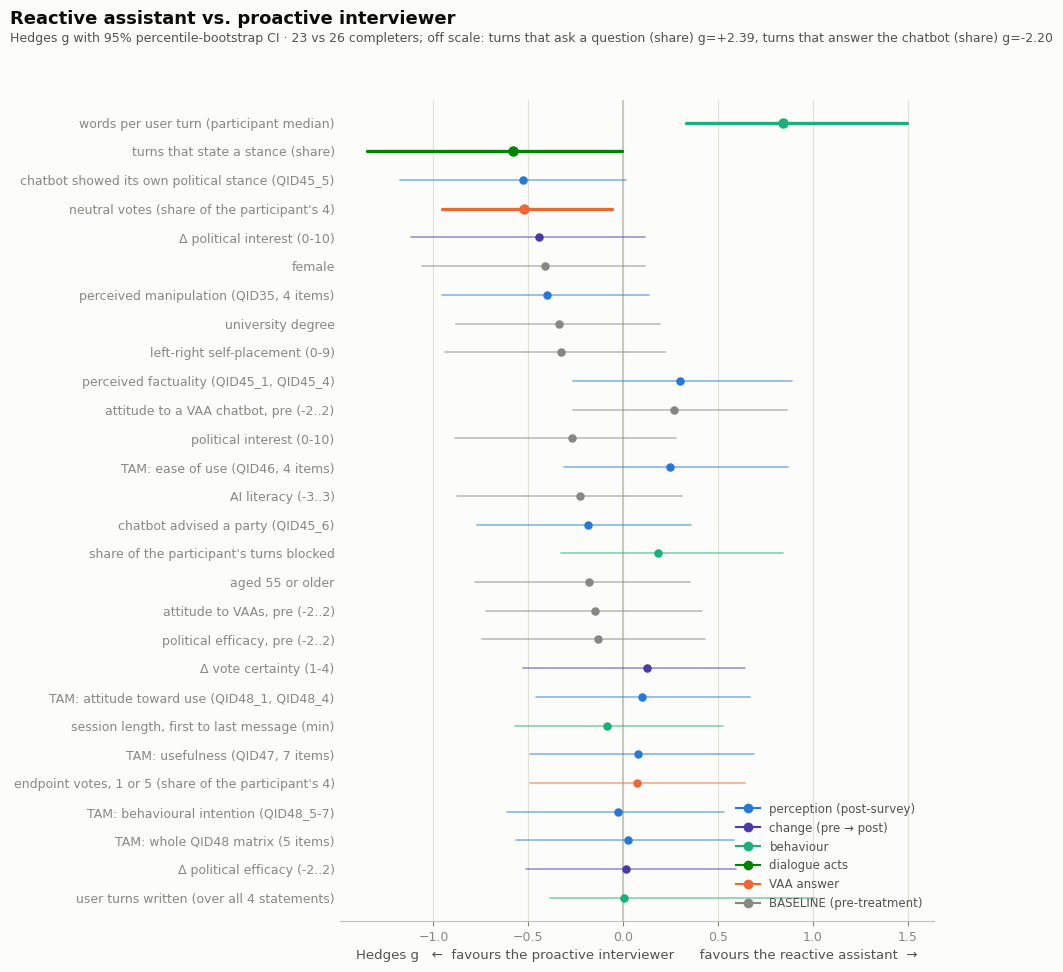

In [19]:
import matplotlib.pyplot as plt

# palette as used in the other study figures
SURFACE, INK, MUTED = "#fcfcfb", "#0b0b0b", "#898781"
SECONDARY, GRID, BASELINE_C = "#52514e", "#e1e0d9", "#c3c2b7"
FAMILY_COLOR = {"perception (post-survey)": "#2a78d6", "change (pre → post)": "#4a3aa7",
                "behaviour": "#1baf7a", "dialogue acts": "#008300",
                "VAA answer": "#eb6834", "BASELINE (pre-treatment)": "#898781"}

OFF_SCALE = 3.0                       # keep the middle of the axis readable
off = everything[(everything["ci_low"].abs() > OFF_SCALE) | (everything["ci_high"].abs() > OFF_SCALE)]
plot = everything.drop(off.index).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 0.29 * len(plot) + 1.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.xaxis.grid(True, color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.axvline(0, color=BASELINE_C, linewidth=1.2, zorder=2)

y = np.arange(len(plot))
for yi, (name, r) in zip(y, plot.iterrows()):
    color = FAMILY_COLOR[r["family"]]
    ax.plot([r["ci_low"], r["ci_high"]], [yi, yi], color=color,
            linewidth=2.4 if r["excludes_0"] else 1.2,
            alpha=1.0 if r["excludes_0"] else 0.55, zorder=3, solid_capstyle="round")
    ax.scatter(r["g"], yi, s=42 if r["excludes_0"] else 26, color=color, zorder=4)

ax.set_yticks(y)
ax.set_yticklabels([n if len(n) < 62 else n[:59] + "…" for n in plot.index], fontsize=8.5)
ax.set_ylim(-0.8, len(plot) - 0.2)
ax.set_xlabel("Hedges g   ←  favours the proactive interviewer      favours the reactive assistant  →",
              color=SECONDARY, fontsize=9.5)
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(BASELINE_C)
ax.tick_params(colors=MUTED, labelsize=9)
ax.tick_params(axis="y", length=0)

handles = [plt.Line2D([], [], color=c, marker="o", linestyle="-", label=f) for f, c in FAMILY_COLOR.items()]
ax.legend(handles=handles, frameon=False, fontsize=8.5, loc="lower right", labelcolor=SECONDARY)

off_note = ("; off scale: " + ", ".join(f"{n} g={r['g']:+.2f}" for n, r in off.iterrows())) if len(off) else ""
fig.suptitle("Reactive assistant vs. proactive interviewer", x=0.012, y=0.995, ha="left",
             fontsize=13, fontweight="bold", color=INK)
fig.text(0.012, 0.962, f"Hedges g with 95% percentile-bootstrap CI · 23 vs 26 completers{off_note}",
         ha="left", fontsize=9, color=SECONDARY)
fig.tight_layout(rect=[0, 0, 1, 0.952])
plt.show()

## 12. Figure: post-survey effect sizes


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


wrote /Users/fybach/Private Stuff/Papers/conversations-cavaa-paper/figures/effect_sizes.pdf  (4.80 x 2.41 in)


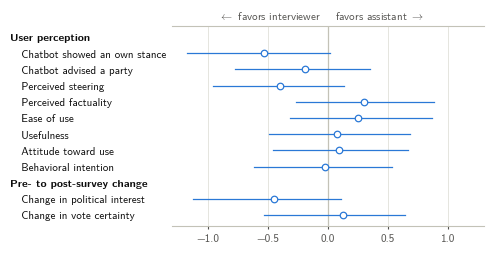

In [20]:
import subprocess
from matplotlib import font_manager

FIG_DIR = (Path(".").resolve() / "../figures").resolve()
TEXTWIDTH_IN = 347.12 / 72.27          # LNCS \textwidth in inches
FONT_PT, ROW_H = 8, 0.155              # \footnotesize, as the pipeline figure's nodes; inches per row
BLUE = FAMILY_COLOR["perception (post-survey)"]


def document_sans():
    """Latin Modern Sans from the TeX tree, the OpenType twin of the paper's \sffamily
    (Computer Modern Sans).  Falls back to matplotlib's default if kpsewhich cannot find it."""
    try:
        for face in ("lmsans10-regular.otf", "lmsans10-bold.otf"):
            path = subprocess.run(["kpsewhich", face], capture_output=True, text=True).stdout.strip()
            font_manager.fontManager.addfont(path)
        return font_manager.FontProperties(fname=path).get_name()
    except (FileNotFoundError, OSError):
        print("Latin Modern Sans not found, using the matplotlib default")
        return "sans-serif"


FONT_FAMILY = document_sans()

# notebook measure -> label in the paper; a measure not listed here is not drawn
PAPER_LABELS = {
    "chatbot showed its own political stance (QID45_5)": "Chatbot showed an own stance",
    "chatbot advised a party (QID45_6)": "Chatbot advised a party",
    "perceived manipulation (QID35, 4 items)": "Perceived steering",
    "perceived factuality (QID45_1, QID45_4)": "Perceived factuality",
    "TAM: ease of use (QID46, 4 items)": "Ease of use",
    "TAM: usefulness (QID47, 7 items)": "Usefulness",
    "TAM: attitude toward use (QID48_1, QID48_4)": "Attitude toward use",
    "TAM: behavioural intention (QID48_5-7)": "Behavioral intention",
    "Δ political interest (0-10)": "Change in political interest",
    "Δ vote certainty (1-4)": "Change in vote certainty",
    "turns that ask a question (share)": "Turns asking a question",
    "turns that answer the chatbot (share)": "Turns answering the chatbot",
    "turns that state a stance (share)": "Turns stating a stance",
    "words per user turn (participant median)": "Words per turn",
    "neutral votes (share of the participant's 4)": "Neutral VAA answers",
}


def paper_rows(table):
    """(label, g, lo, hi) for the rows of `table` that have a paper label, in table order."""
    return [(PAPER_LABELS[m], r["g"], r["ci_low"], r["ci_high"])
            for m, r in table.iterrows() if m in PAPER_LABELS]


PERCEPTION_BLOCKS = [
    ("User perception", paper_rows(effect_table(perception, cond))),
    ("Pre- to post-survey change", paper_rows(effect_table(change, cond))),
]

# conversation-level measures
conversation_table = pd.concat([
    effect_table(kept[["question", "answer", "stance"]].set_axis(ACT_MEASURES, axis=1), kept["condition"]),
    effect_table(behaviour_complete[["median_words"]], behaviour_complete["condition"], labels=BEHAVIOUR_LABELS),
    effect_table(by_participant[["neutral"]].set_axis(VOTE_MEASURES[:1], axis=1), by_participant["condition"]),
])
CONVERSATION_BLOCK = ("Conversation patterns", paper_rows(conversation_table) + [
    (name, None, None, None) for name in ("Source attribution", "Directive framing", "Stance leakage",
                                          "Prompted reflection", "Unprompted reflection")])


def draw_forest(blocks, out_path, x_lim, x_ticks):
    """One row per measure, grouped under bold headings.  Filled marker: interval excludes zero.
    An interval end beyond ±x_lim becomes an arrow; a point estimate beyond it is written as
    text on the other side of zero.  A row with g=None is a grey placeholder."""
    rows = []
    for heading, entries in blocks:
        rows.append(("heading", heading, None, None, None))
        rows += [("placeholder" if g is None else "row", label, g, lo, hi) for label, g, lo, hi in entries]

    with plt.rc_context({"font.size": FONT_PT, "font.family": FONT_FAMILY, "mathtext.fontset": "cm",
                         "pdf.fonttype": 42}):
        fig, ax = plt.subplots(figsize=(TEXTWIDTH_IN, ROW_H * len(rows) + 0.55))
        ax.set_axisbelow(True)
        ax.xaxis.grid(True, color=GRID, linewidth=0.6)
        ax.axvline(0, color=BASELINE_C, linewidth=0.9, zorder=2)

        ticks = []
        for i, (kind, label, g, lo, hi) in enumerate(rows):
            y = len(rows) - 1 - i
            if kind == "heading":
                ticks.append((y, label, INK, "bold"))
                continue
            if kind == "placeholder":
                ticks.append((y, "   " + label, MUTED, "normal"))
                ax.plot([-x_lim, x_lim], [y, y], color=GRID, linewidth=0.6, linestyle=(0, (1, 3)), zorder=1)
                ax.text(x_lim, y, "pending ", ha="right", va="center", fontsize=FONT_PT - 1, color=MUTED)
                continue
            ticks.append((y, "   " + label, INK, "normal"))
            clear = lo > 0 or hi < 0
            lo_c, hi_c = max(lo, -x_lim), min(hi, x_lim)
            if lo_c < hi_c:
                ax.plot([lo_c, hi_c], [y, y], color=BLUE, linewidth=1.3 if clear else 0.9, zorder=3)
            for off_scale, side in ((lo < -x_lim, -1), (hi > x_lim, 1)):
                if off_scale:
                    ax.annotate("", xy=(side * x_lim, y), xytext=(side * (x_lim - 0.12), y), zorder=3,
                                arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=0.9, shrinkA=0, shrinkB=0))
            if abs(g) <= x_lim:
                ax.scatter(g, y, s=22, facecolor=BLUE if clear else "white", edgecolor=BLUE,
                           linewidth=0.9, zorder=4)
            else:
                side = np.sign(g)
                ax.text(-side * 0.08, y, f"$g={g:+.2f}$ [{lo:+.2f}, {hi:+.2f}]", va="center",
                        ha="right" if side > 0 else "left", fontsize=FONT_PT - 1, color=SECONDARY, zorder=5)

        ax.set_yticks([t[0] for t in ticks])
        ax.set_yticklabels([t[1] for t in ticks], ha="left", fontsize=FONT_PT)
        for tick, (_, _, color, weight) in zip(ax.get_yticklabels(), ticks):
            tick.set_color(color)
            tick.set_fontweight(weight)
        fig.canvas.draw()                                   # left-aligned labels need the column width
        pad_pt = max(t.get_window_extent().width for t in ax.get_yticklabels()) * 72 / fig.dpi
        ax.tick_params(axis="y", pad=pad_pt + 4, length=0)

        ax.set_ylim(-0.7, len(rows) - 0.3)
        ax.set_xlim(-x_lim, x_lim)
        ax.set_xticks(x_ticks)
        ax.tick_params(axis="x", colors=SECONDARY, length=2, labelsize=FONT_PT)
        for x, text, ha in ((-0.06, r"$\leftarrow$ favors interviewer", "right"),
                            (0.06, r"favors assistant $\rightarrow$", "left")):
            ax.annotate(text, xy=(x, 1), xycoords=("data", "axes fraction"), xytext=(0, 3),
                        textcoords="offset points", ha=ha, va="bottom", fontsize=FONT_PT,
                        color=SECONDARY, annotation_clip=False)
        for spine in ("right", "left"):
            ax.spines[spine].set_visible(False)
        for spine in ("top", "bottom"):
            ax.spines[spine].set_color(BASELINE_C)

        fig.tight_layout(pad=0.3)
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_path)
        print(f"wrote {out_path}  ({TEXTWIDTH_IN:.2f} x {fig.get_figheight():.2f} in)")
        plt.show()


draw_forest(PERCEPTION_BLOCKS, FIG_DIR / "effect_sizes.pdf", x_lim=1.3, x_ticks=[-1, -0.5, 0, 0.5, 1])
# draw_forest([CONVERSATION_BLOCK], FIG_DIR / "effect_sizes_conversation.pdf",
#             x_lim=1.6, x_ticks=[-1.5, -1, -0.5, 0, 0.5, 1, 1.5])
